In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv('cognifyz_restaurant_rating_dataset.csv')

print("Dataset loaded successfully!")

Saving cognifyz_restaurant_rating_dataset.csv to cognifyz_restaurant_rating_dataset.csv
Dataset loaded successfully!


In [3]:
df = pd.read_csv('cognifyz_restaurant_rating_dataset.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
# Display first five rows

df.head()

,Restaurant ID,City,Cuisines,Votes,Average Cost for two,Price range,Has Online delivery,Has Table booking,Aggregate rating
0,100001,New Delhi,Desserts,2195,1500,3,No,No,2.7
1,100002,Chennai,Continental,156,1200,2,Yes,No,2.4
2,100003,Hyderabad,Cafe,994,2500,4,No,Yes,4.2
3,100004,Bengaluru,Desserts,1146,2500,4,No,No,4.5
4,100005,Bengaluru,Chinese,1994,1200,2,Yes,Yes,2.9


In [5]:
# Dataset dimensions

print("Dataset Shape:", df.shape)

# Dataset information

df.info()

# Statistical summary

df.describe()

Dataset Shape: (1000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         1000 non-null   int64  
 1   City                  1000 non-null   object 
 2   Cuisines              1000 non-null   object 
 3   Votes                 1000 non-null   int64  
 4   Average Cost for two  1000 non-null   int64  
 5   Price range           1000 non-null   int64  
 6   Has Online delivery   1000 non-null   object 
 7   Has Table booking     1000 non-null   object 
 8   Aggregate rating      1000 non-null   float64
dtypes: float64(1), int64(4), object(4)
memory usage: 70.4+ KB


,Restaurant ID,Votes,Average Cost for two,Price range,Aggregate rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,100500.500000,1258.910000,1000.100000,1.997000,2.926000
std,288.819436,722.112801,705.994631,1.124391,0.525166
min,100001.000000,2.000000,200.000000,1.000000,1.400000
25%,100250.750000,642.500000,400.000000,1.000000,2.600000
50%,100500.500000,1229.500000,800.000000,2.000000,2.900000
75%,100750.250000,1886.750000,1500.000000,3.000000,3.300000
max,101000.000000,2498.000000,2500.000000,4.000000,4.900000


In [6]:
# Count restaurants in each cuisine category

cuisine_counts = df['Cuisines'].value_counts()

print(cuisine_counts)

Cuisines
Chinese         105
Desserts        103
Italian         103
Cafe            103
Continental     101
Street Food     101
North Indian    101
Fast Food       100
South Indian     98
Mexican          85
Name: count, dtype: int64


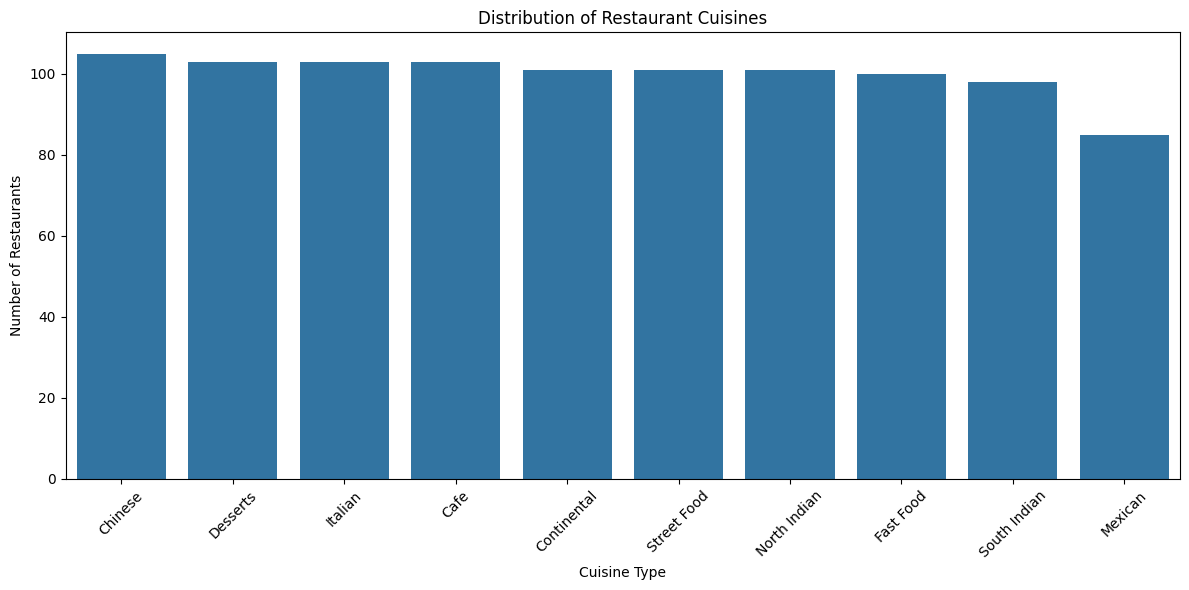

In [7]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='Cuisines',
    order=df['Cuisines'].value_counts().index
)

plt.title('Distribution of Restaurant Cuisines')
plt.xlabel('Cuisine Type')
plt.ylabel('Number of Restaurants')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
cuisine_percentage = (
    df['Cuisines'].value_counts(normalize=True) * 100
)

print("Cuisine Percentage Distribution:")
print(cuisine_percentage.round(2))

Cuisine Percentage Distribution:
Cuisines
Chinese         10.5
Desserts        10.3
Italian         10.3
Cafe            10.3
Continental     10.1
Street Food     10.1
North Indian    10.1
Fast Food       10.0
South Indian     9.8
Mexican          8.5
Name: proportion, dtype: float64


In [9]:
# Select numerical columns

numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
)

print(numerical_columns.describe())

       Restaurant ID        Votes  Average Cost for two  Price range  \
count    1000.000000  1000.000000           1000.000000  1000.000000   
mean   100500.500000  1258.910000           1000.100000     1.997000   
std       288.819436   722.112801            705.994631     1.124391   
min    100001.000000     2.000000            200.000000     1.000000   
25%    100250.750000   642.500000            400.000000     1.000000   
50%    100500.500000  1229.500000            800.000000     2.000000   
75%    100750.250000  1886.750000           1500.000000     3.000000   
max    101000.000000  2498.000000           2500.000000     4.000000   

       Aggregate rating  
count       1000.000000  
mean           2.926000  
std            0.525166  
min            1.400000  
25%            2.600000  
50%            2.900000  
75%            3.300000  
max            4.900000  


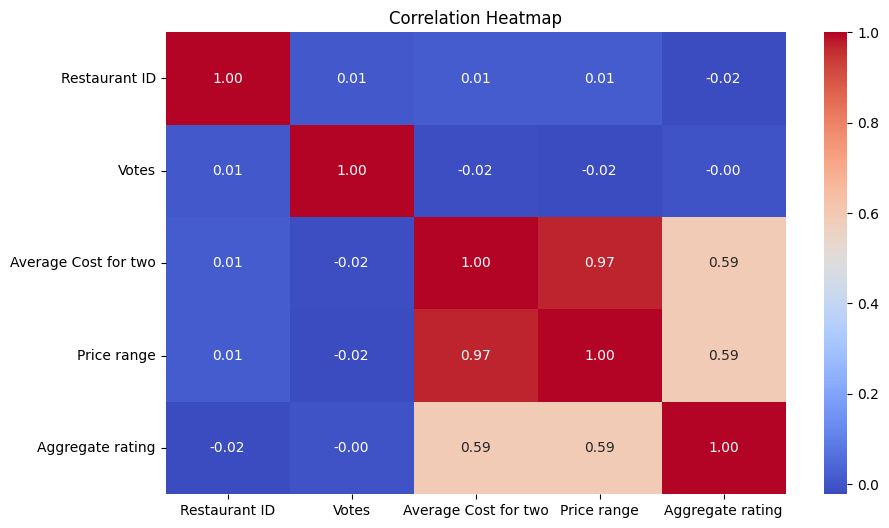

In [10]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    numerical_columns.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [11]:
# Identify categorical columns

categorical_columns = df.select_dtypes(
    include=['object']
).columns

print("Categorical Columns:")
print(categorical_columns)

# Identify numerical columns

numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns

print("\nNumerical Columns:")
print(numerical_columns)

Categorical Columns:
Index(['City', 'Cuisines', 'Has Online delivery', 'Has Table booking'], dtype='object')

Numerical Columns:
Index(['Restaurant ID', 'Votes', 'Average Cost for two', 'Price range',
       'Aggregate rating'],
      dtype='object')


In [12]:
# Define target variable

y = df['Cuisines']

# Select input features

X = df.drop(
    columns=['Cuisines', 'Restaurant ID', 'Aggregate rating']
)

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
        City  Votes  Average Cost for two  Price range Has Online delivery  \
0  New Delhi   2195                  1500            3                  No   
1    Chennai    156                  1200            2                 Yes   
2  Hyderabad    994                  2500            4                  No   
3  Bengaluru   1146                  2500            4                  No   
4  Bengaluru   1994                  1200            2                 Yes   

  Has Table booking  
0                No  
1                No  
2               Yes  
3                No  
4               Yes  

Target Variable:
0       Desserts
1    Continental
2           Cafe
3       Desserts
4        Chinese
Name: Cuisines, dtype: object


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identify categorical and numerical features

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Create preprocessing transformer

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ],
    remainder='passthrough'
)

print("Preprocessing transformer created successfully!")

Preprocessing transformer created successfully!


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Data Shape: (800, 6)
Testing Data Shape: (200, 6)

Training Target Shape: (800,)
Testing Target Shape: (200,)


In [15]:
# Fit preprocessing on training data only

X_train_encoded = preprocessor.fit_transform(X_train)

# Transform testing data

X_test_encoded = preprocessor.transform(X_test)

print("Training data encoded successfully!")
print("Testing data encoded successfully!")

print("\nEncoded Training Shape:", X_train_encoded.shape)
print("Encoded Testing Shape:", X_test_encoded.shape)

Training data encoded successfully!
Testing data encoded successfully!

Encoded Training Shape: (800, 17)
Encoded Testing Shape: (200, 17)


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

print("Classification algorithms imported successfully!")

Classification algorithms imported successfully!


In [17]:
# Create Logistic Regression model

lr_model = LogisticRegression(max_iter=2000)

# Train the model

lr_model.fit(X_train_encoded, y_train)

# Make predictions

lr_predictions = lr_model.predict(X_test_encoded)

print("Logistic Regression Model trained successfully!")

Logistic Regression Model trained successfully!


In [18]:
# Create Random Forest model

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model

rf_model.fit(X_train_encoded, y_train)

# Make predictions

rf_predictions = rf_model.predict(X_test_encoded)

print("Random Forest Model trained successfully!")

Random Forest Model trained successfully!


In [19]:
from sklearn.metrics import accuracy_score

# Calculate accuracy

lr_accuracy = accuracy_score(y_test, lr_predictions)

rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Logistic Regression Accuracy:",
      round(lr_accuracy * 100, 2), "%")

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 11.0 %
Random Forest Accuracy: 8.5 %


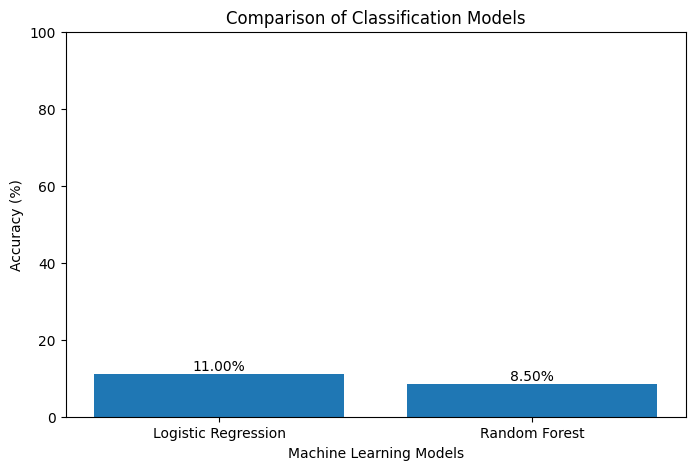

In [20]:
models = ['Logistic Regression', 'Random Forest']

accuracies = [
    lr_accuracy * 100,
    rf_accuracy * 100
]

plt.figure(figsize=(8, 5))

plt.bar(models, accuracies)

plt.title('Comparison of Classification Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy (%)')

plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 1, f'{value:.2f}%',
             ha='center')

plt.show()

In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Logistic Regression evaluation

print("LOGISTIC REGRESSION RESULTS")

print("Accuracy:",
      accuracy_score(y_test, lr_predictions))

print("Precision:",
      precision_score(y_test, lr_predictions,
                      average='weighted', zero_division=0))

print("Recall:",
      recall_score(y_test, lr_predictions,
                   average='weighted', zero_division=0))

print("F1 Score:",
      f1_score(y_test, lr_predictions,
               average='weighted', zero_division=0))


# Random Forest evaluation

print("\nRANDOM FOREST RESULTS")

print("Accuracy:",
      accuracy_score(y_test, rf_predictions))

print("Precision:",
      precision_score(y_test, rf_predictions,
                      average='weighted', zero_division=0))

print("Recall:",
      recall_score(y_test, rf_predictions,
                   average='weighted', zero_division=0))

print("F1 Score:",
      f1_score(y_test, rf_predictions,
               average='weighted', zero_division=0))

LOGISTIC REGRESSION RESULTS
Accuracy: 0.11
Precision: 0.10684184236815815
Recall: 0.11
F1 Score: 0.10225541584122093

RANDOM FOREST RESULTS
Accuracy: 0.085
Precision: 0.08497669996505638
Recall: 0.085
F1 Score: 0.08462806688579665


In [22]:
print("LOGISTIC REGRESSION CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    lr_predictions,
    zero_division=0
))

print("\nRANDOM FOREST CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    rf_predictions,
    zero_division=0
))

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Cafe       0.07      0.10      0.08        21
     Chinese       0.00      0.00      0.00        21
 Continental       0.05      0.05      0.05        20
    Desserts       0.11      0.19      0.14        21
   Fast Food       0.14      0.25      0.18        20
     Italian       0.09      0.05      0.06        21
     Mexican       0.00      0.00      0.00        17
North Indian       0.12      0.05      0.07        20
South Indian       0.31      0.21      0.25        19
 Street Food       0.18      0.20      0.19        20

    accuracy                           0.11       200
   macro avg       0.11      0.11      0.10       200
weighted avg       0.11      0.11      0.10       200


RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Cafe       0.04      0.05      0.04        21
     Chinese       0.06      0.05      0.05        21

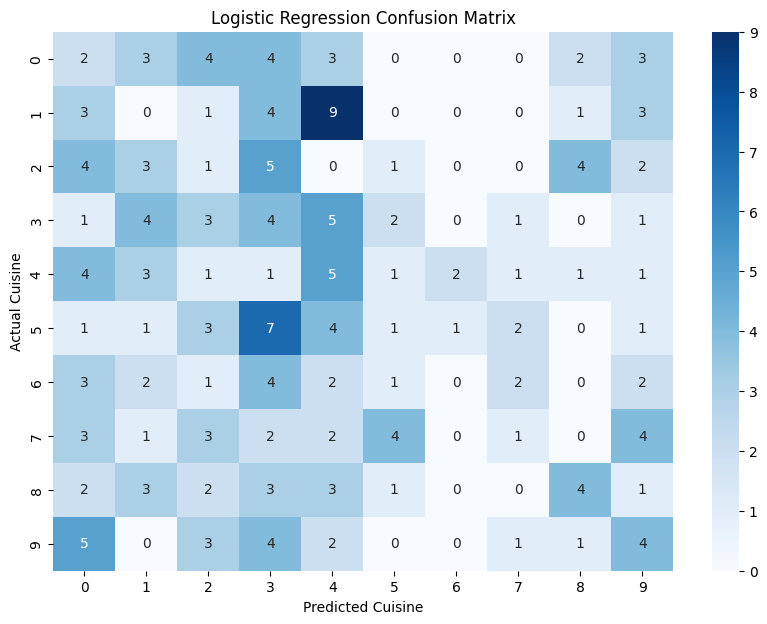

In [23]:
plt.figure(figsize=(10, 7))

cm_lr = confusion_matrix(y_test, lr_predictions)

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted Cuisine')
plt.ylabel('Actual Cuisine')

plt.show()

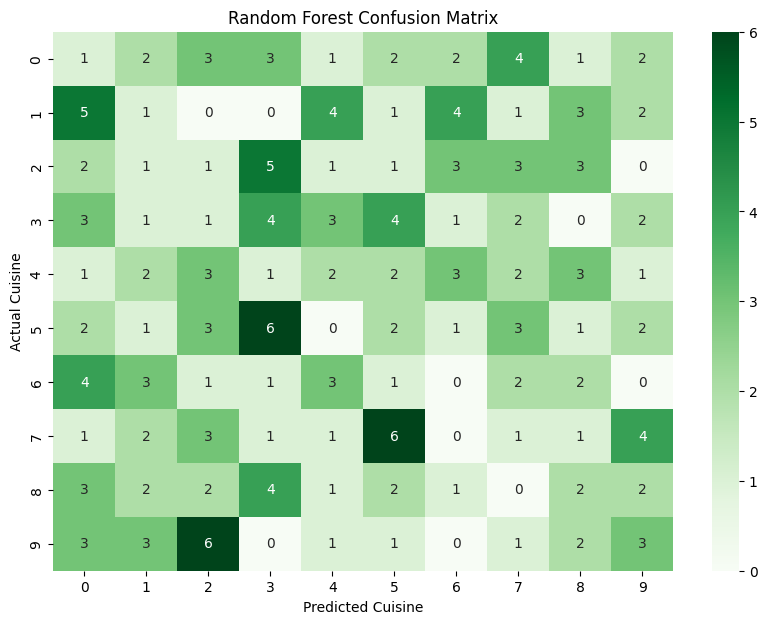

In [24]:
plt.figure(figsize=(10, 7))

cm_rf = confusion_matrix(y_test, rf_predictions)

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted Cuisine')
plt.ylabel('Actual Cuisine')

plt.show()

In [25]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],

    'Accuracy': [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions)
    ],

    'Precision': [
        precision_score(y_test, lr_predictions,
                        average='weighted', zero_division=0),
        precision_score(y_test, rf_predictions,
                        average='weighted', zero_division=0)
    ],

    'Recall': [
        recall_score(y_test, lr_predictions,
                     average='weighted', zero_division=0),
        recall_score(y_test, rf_predictions,
                     average='weighted', zero_division=0)
    ],

    'F1 Score': [
        f1_score(y_test, lr_predictions,
                 average='weighted', zero_division=0),
        f1_score(y_test, rf_predictions,
                 average='weighted', zero_division=0)
    ]
})

print(results)

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression     0.110   0.106842   0.110  0.102255
1        Random Forest     0.085   0.084977   0.085  0.084628


In [26]:
from sklearn.metrics import classification_report

# Generate classification report

report = classification_report(
    y_test,
    rf_predictions,
    output_dict=True,
    zero_division=0
)

# Convert report into DataFrame

report_df = pd.DataFrame(report).transpose()

# Display cuisine-wise performance

print("Cuisine-wise Performance Analysis:")

print(report_df.iloc[:-3][
    ['precision', 'recall', 'f1-score', 'support']
])

Cuisine-wise Performance Analysis:
              precision    recall  f1-score  support
Cafe           0.040000  0.047619  0.043478     21.0
Chinese        0.055556  0.047619  0.051282     21.0
Continental    0.043478  0.050000  0.046512     20.0
Desserts       0.160000  0.190476  0.173913     21.0
Fast Food      0.117647  0.100000  0.108108     20.0
Italian        0.090909  0.095238  0.093023     21.0
Mexican        0.000000  0.000000  0.000000     17.0
North Indian   0.052632  0.050000  0.051282     20.0
South Indian   0.111111  0.105263  0.108108     19.0
Street Food    0.166667  0.150000  0.157895     20.0


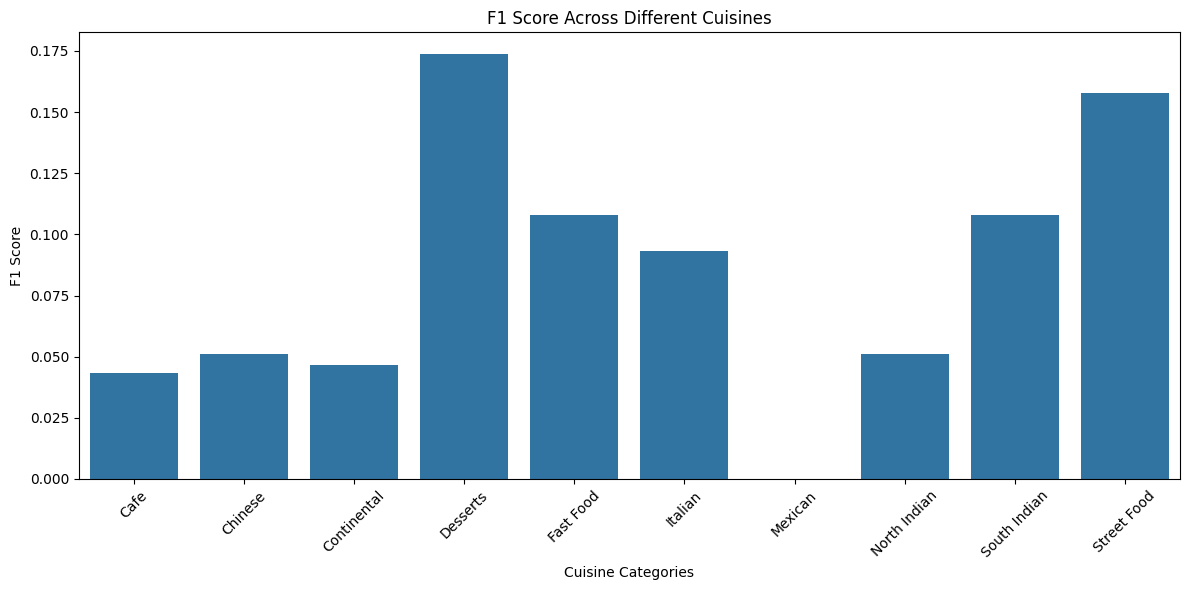

In [27]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=report_df.index[:-3],
    y=report_df['f1-score'][:-3]
)

plt.title('F1 Score Across Different Cuisines')
plt.xlabel('Cuisine Categories')
plt.ylabel('F1 Score')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [28]:
cuisine_performance = report_df.iloc[:-3]

best_cuisine = cuisine_performance['f1-score'].idxmax()

worst_cuisine = cuisine_performance['f1-score'].idxmin()

print("Best Predicted Cuisine:", best_cuisine)

print("Best F1 Score:",
      round(cuisine_performance.loc[best_cuisine, 'f1-score'], 3))

print("\nWorst Predicted Cuisine:", worst_cuisine)

print("Worst F1 Score:",
      round(cuisine_performance.loc[worst_cuisine, 'f1-score'], 3))

Best Predicted Cuisine: Desserts
Best F1 Score: 0.174

Worst Predicted Cuisine: Mexican
Worst F1 Score: 0.0


In [29]:
cuisine_counts = df['Cuisines'].value_counts()

print("Most Common Cuisine:")
print(cuisine_counts.head(3))

print("\nLeast Common Cuisine:")
print(cuisine_counts.tail(3))

Most Common Cuisine:
Cuisines
Chinese     105
Desserts    103
Italian     103
Name: count, dtype: int64

Least Common Cuisine:
Cuisines
Fast Food       100
South Indian     98
Mexican          85
Name: count, dtype: int64


In [30]:
comparison = pd.DataFrame({
    'Actual Cuisine': y_test.values,
    'Predicted Cuisine': rf_predictions
})

print(comparison.head(20))

   Actual Cuisine Predicted Cuisine
0         Italian       Continental
1            Cafe       Continental
2    South Indian           Italian
3     Continental          Desserts
4     Street Food       Street Food
5        Desserts       Continental
6        Desserts         Fast Food
7            Cafe          Desserts
8            Cafe       Street Food
9            Cafe         Fast Food
10       Desserts       Street Food
11   South Indian              Cafe
12           Cafe           Chinese
13    Street Food              Cafe
14   North Indian           Italian
15        Italian              Cafe
16    Continental          Desserts
17    Continental           Mexican
18        Chinese         Fast Food
19        Italian          Desserts


# Conclusion – Cuisine Classification

In this project, I developed a machine learning model to classify restaurants based on their cuisines using the Cognifyz restaurant dataset.

The project involved data preprocessing, exploratory data analysis, categorical feature encoding, and splitting the dataset into training and testing sets.

Two classification algorithms were implemented:

1. Logistic Regression
2. Random Forest Classifier

Both models were evaluated using accuracy, precision, recall, F1-score, and confusion matrices.

Cuisine-wise performance analysis was also conducted to understand how effectively the models classified different cuisine categories.

The project helped demonstrate the application of machine learning classification techniques in restaurant data analysis.

The results also highlighted challenges such as overlapping restaurant characteristics, limited dataset size, and potential class imbalance.

In [32]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [33]:
# Create pipeline

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=5000))
])

print("Machine Learning Pipeline Created Successfully!")

Machine Learning Pipeline Created Successfully!


In [34]:
# Define parameter grid

param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__class_weight': [None, 'balanced']
}

print("Hyperparameter Grid Created Successfully!")

Hyperparameter Grid Created Successfully!


In [35]:
# Create cross-validation strategy

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Apply Grid Search

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

# Train Grid Search

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(round(grid_search.best_score_ * 100, 2), "%")

Best Parameters:
{'classifier__C': 10, 'classifier__class_weight': None}

Best Cross-Validation Accuracy:
13.25 %


In [36]:
# Get the best model

best_model = grid_search.best_estimator_

# Predict test data

improved_predictions = best_model.predict(X_test)

# Calculate accuracy

improved_accuracy = accuracy_score(
    y_test,
    improved_predictions
)

print("Improved Model Accuracy:",
      round(improved_accuracy * 100, 2), "%")

Improved Model Accuracy: 11.5 %


                          Model  Accuracy
0           Logistic Regression      11.0
1                 Random Forest       8.5
2  Improved Logistic Regression      11.5


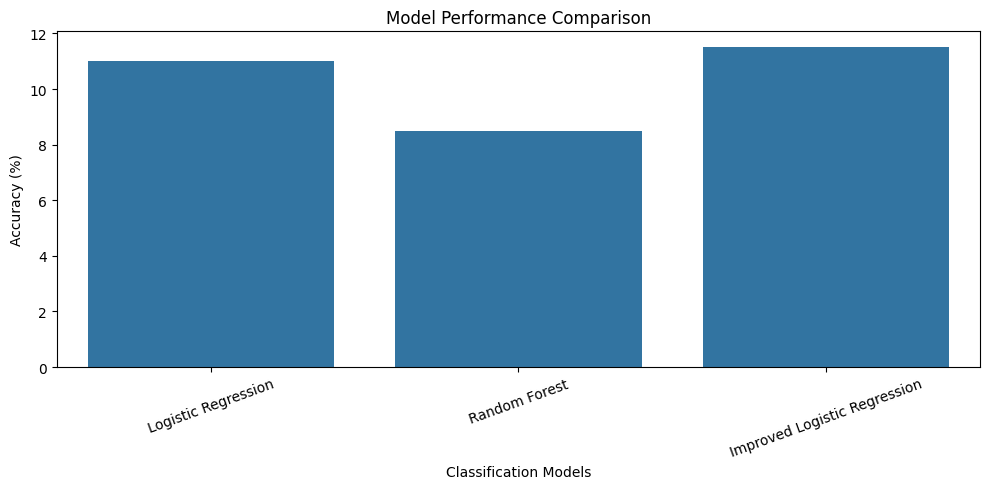

In [37]:
comparison_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Improved Logistic Regression'
    ],

    'Accuracy': [
        accuracy_score(y_test, lr_predictions) * 100,
        accuracy_score(y_test, rf_predictions) * 100,
        improved_accuracy * 100
    ]
})

print(comparison_results)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparison_results,
    x='Model',
    y='Accuracy'
)

plt.title('Model Performance Comparison')
plt.ylabel('Accuracy (%)')
plt.xlabel('Classification Models')

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Challenges and Limitations

During the cuisine classification project, several challenges were identified:

1. Low Prediction Accuracy: The classification models achieved relatively low accuracy, indicating limited predictive information in the available features.

2. Similar Restaurant Characteristics: Different restaurants may have similar prices, ratings, locations and service options despite offering different cuisines.

3. Limited Dataset Size: The dataset contains only 1,000 restaurant records, which may limit the model's ability to learn complex patterns.

4. Feature Limitations: The available features may not adequately represent the actual cuisine characteristics of restaurants.

5. Model Optimization: Hyperparameter tuning and cross-validation were used to improve model selection and evaluate performance more reliably.

These limitations indicate that additional cuisine-related information could be useful for developing a more accurate classification model.

In [38]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

# Consistent visual theme for all project charts
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({
    "figure.figsize": (11, 6),
    "figure.dpi": 120,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.25
})

print("Visualization theme configured successfully!")


All libraries imported successfully!
Visualization theme configured successfully!


In [39]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv('cognifyz_restaurant_rating_dataset.csv')

print("Dataset loaded successfully!")

Saving cognifyz_restaurant_rating_dataset.csv to cognifyz_restaurant_rating_dataset (1).csv
Dataset loaded successfully!


In [40]:
df = pd.read_csv('cognifyz_restaurant_rating_dataset.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [41]:
# Display first five rows

df.head()

,Restaurant ID,City,Cuisines,Votes,Average Cost for two,Price range,Has Online delivery,Has Table booking,Aggregate rating
0,100001,New Delhi,Desserts,2195,1500,3,No,No,2.7
1,100002,Chennai,Continental,156,1200,2,Yes,No,2.4
2,100003,Hyderabad,Cafe,994,2500,4,No,Yes,4.2
3,100004,Bengaluru,Desserts,1146,2500,4,No,No,4.5
4,100005,Bengaluru,Chinese,1994,1200,2,Yes,Yes,2.9


In [42]:
# Dataset dimensions

print("Dataset Shape:", df.shape)

# Dataset information

df.info()

# Statistical summary

df.describe()

Dataset Shape: (1000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         1000 non-null   int64  
 1   City                  1000 non-null   object 
 2   Cuisines              1000 non-null   object 
 3   Votes                 1000 non-null   int64  
 4   Average Cost for two  1000 non-null   int64  
 5   Price range           1000 non-null   int64  
 6   Has Online delivery   1000 non-null   object 
 7   Has Table booking     1000 non-null   object 
 8   Aggregate rating      1000 non-null   float64
dtypes: float64(1), int64(4), object(4)
memory usage: 70.4+ KB


,Restaurant ID,Votes,Average Cost for two,Price range,Aggregate rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,100500.500000,1258.910000,1000.100000,1.997000,2.926000
std,288.819436,722.112801,705.994631,1.124391,0.525166
min,100001.000000,2.000000,200.000000,1.000000,1.400000
25%,100250.750000,642.500000,400.000000,1.000000,2.600000
50%,100500.500000,1229.500000,800.000000,2.000000,2.900000
75%,100750.250000,1886.750000,1500.000000,3.000000,3.300000
max,101000.000000,2498.000000,2500.000000,4.000000,4.900000


In [43]:
# Count restaurants in each cuisine category

cuisine_counts = df['Cuisines'].value_counts()

print(cuisine_counts)

Cuisines
Chinese         105
Desserts        103
Italian         103
Cafe            103
Continental     101
Street Food     101
North Indian    101
Fast Food       100
South Indian     98
Mexican          85
Name: count, dtype: int64


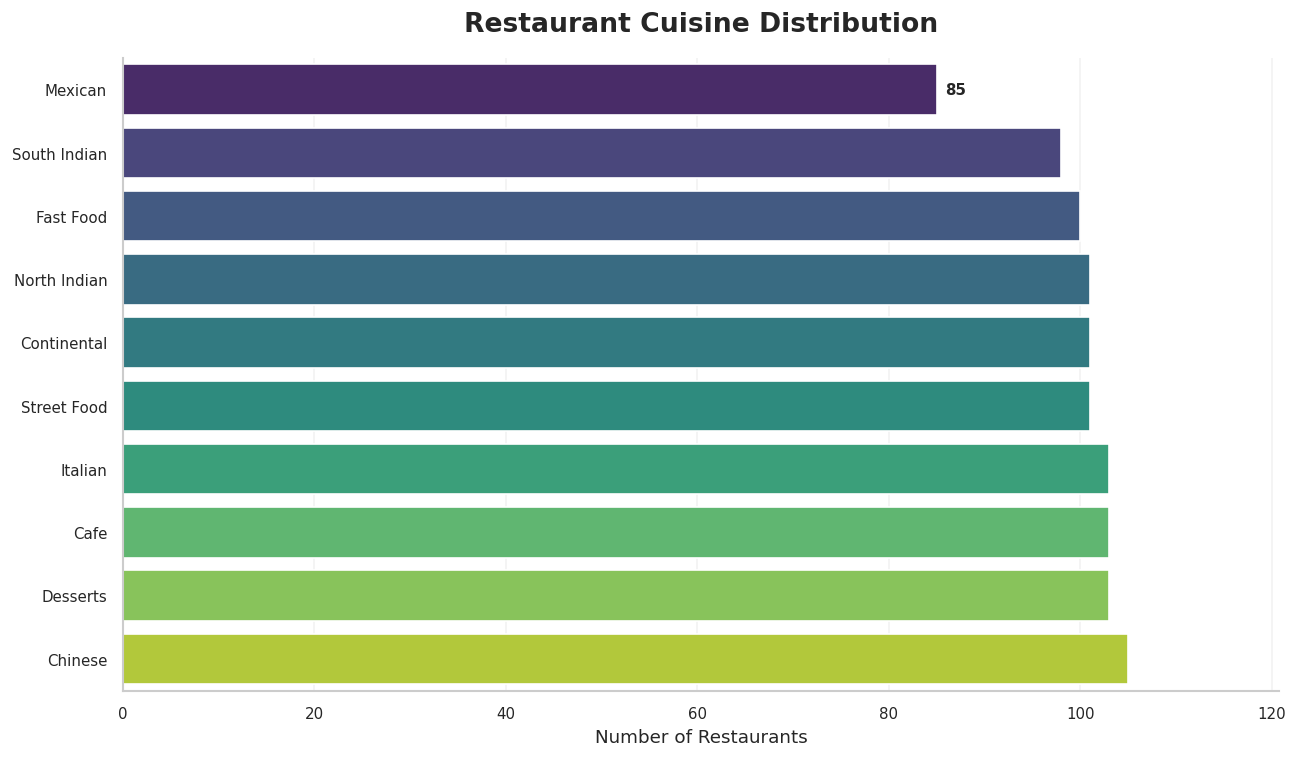

In [44]:
# Restaurant cuisine distribution – sorted horizontal bar chart
cuisine_counts = df['Cuisines'].value_counts().sort_values(ascending=True)
plot_data = cuisine_counts.reset_index()
plot_data.columns = ['Cuisine', 'Restaurant Count']

fig, ax = plt.subplots(figsize=(11, 6.5))
bars = sns.barplot(
    data=plot_data,
    x='Restaurant Count',
    y='Cuisine',
    hue='Cuisine',
    dodge=False,
    palette=sns.color_palette("viridis", n_colors=len(plot_data)),
    legend=False,
    ax=ax
)

ax.set_title('Restaurant Cuisine Distribution', pad=16)
ax.set_xlabel('Number of Restaurants')
ax.set_ylabel('')
ax.bar_label(bars.containers[0], padding=5, fontsize=9, fontweight='bold')
ax.grid(axis='x', alpha=0.25)
ax.grid(axis='y', visible=False)
ax.set_xlim(0, plot_data['Restaurant Count'].max() * 1.15)
plt.tight_layout()
plt.show()


In [45]:
cuisine_percentage = (
    df['Cuisines'].value_counts(normalize=True) * 100
)

print("Cuisine Percentage Distribution:")
print(cuisine_percentage.round(2))

Cuisine Percentage Distribution:
Cuisines
Chinese         10.5
Desserts        10.3
Italian         10.3
Cafe            10.3
Continental     10.1
Street Food     10.1
North Indian    10.1
Fast Food       10.0
South Indian     9.8
Mexican          8.5
Name: proportion, dtype: float64


In [46]:
# Select numerical columns

numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
)

print(numerical_columns.describe())

       Restaurant ID        Votes  Average Cost for two  Price range  \
count    1000.000000  1000.000000           1000.000000  1000.000000   
mean   100500.500000  1258.910000           1000.100000     1.997000   
std       288.819436   722.112801            705.994631     1.124391   
min    100001.000000     2.000000            200.000000     1.000000   
25%    100250.750000   642.500000            400.000000     1.000000   
50%    100500.500000  1229.500000            800.000000     2.000000   
75%    100750.250000  1886.750000           1500.000000     3.000000   
max    101000.000000  2498.000000           2500.000000     4.000000   

       Aggregate rating  
count       1000.000000  
mean           2.926000  
std            0.525166  
min            1.400000  
25%            2.600000  
50%            2.900000  
75%            3.300000  
max            4.900000  


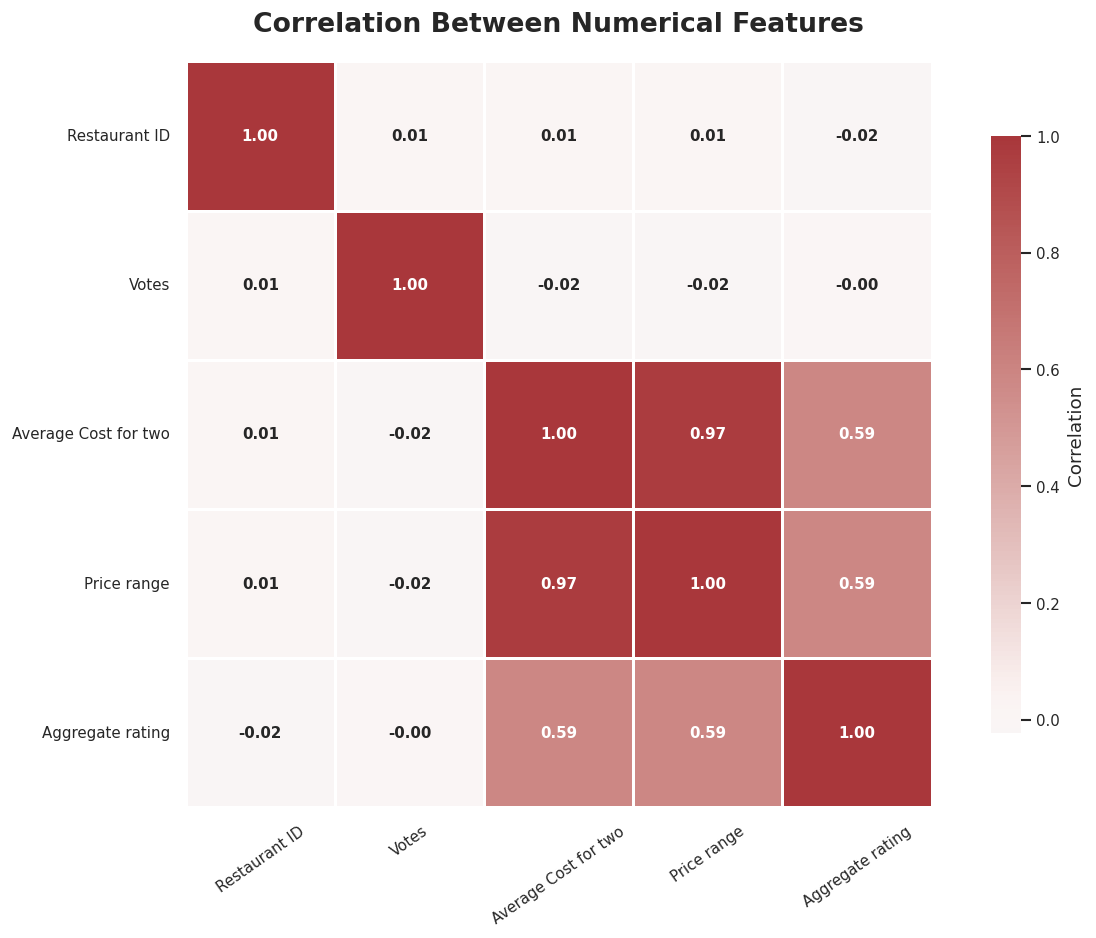

In [47]:
# Correlation heatmap for numerical features
corr = numerical_columns.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='vlag',
    center=0,
    linewidths=0.8,
    linecolor='white',
    square=True,
    cbar_kws={'shrink': 0.8, 'label': 'Correlation'},
    annot_kws={'size': 9, 'weight': 'bold'},
    ax=ax
)

ax.set_title('Correlation Between Numerical Features', pad=18)
ax.tick_params(axis='x', rotation=35)
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.show()


In [48]:
# Identify categorical columns

categorical_columns = df.select_dtypes(
    include=['object']
).columns

print("Categorical Columns:")
print(categorical_columns)

# Identify numerical columns

numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns

print("\nNumerical Columns:")
print(numerical_columns)

Categorical Columns:
Index(['City', 'Cuisines', 'Has Online delivery', 'Has Table booking'], dtype='object')

Numerical Columns:
Index(['Restaurant ID', 'Votes', 'Average Cost for two', 'Price range',
       'Aggregate rating'],
      dtype='object')


In [49]:
# Define target variable

y = df['Cuisines']

# Select input features

X = df.drop(
    columns=['Cuisines', 'Restaurant ID', 'Aggregate rating']
)

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
        City  Votes  Average Cost for two  Price range Has Online delivery  \
0  New Delhi   2195                  1500            3                  No   
1    Chennai    156                  1200            2                 Yes   
2  Hyderabad    994                  2500            4                  No   
3  Bengaluru   1146                  2500            4                  No   
4  Bengaluru   1994                  1200            2                 Yes   

  Has Table booking  
0                No  
1                No  
2               Yes  
3                No  
4               Yes  

Target Variable:
0       Desserts
1    Continental
2           Cafe
3       Desserts
4        Chinese
Name: Cuisines, dtype: object


In [50]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identify categorical and numerical features

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Create preprocessing transformer

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ],
    remainder='passthrough'
)

print("Preprocessing transformer created successfully!")

Preprocessing transformer created successfully!


In [51]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Data Shape: (800, 6)
Testing Data Shape: (200, 6)

Training Target Shape: (800,)
Testing Target Shape: (200,)


In [52]:
# Fit preprocessing on training data only

X_train_encoded = preprocessor.fit_transform(X_train)

# Transform testing data

X_test_encoded = preprocessor.transform(X_test)

print("Training data encoded successfully!")
print("Testing data encoded successfully!")

print("\nEncoded Training Shape:", X_train_encoded.shape)
print("Encoded Testing Shape:", X_test_encoded.shape)

Training data encoded successfully!
Testing data encoded successfully!

Encoded Training Shape: (800, 17)
Encoded Testing Shape: (200, 17)


In [53]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

print("Classification algorithms imported successfully!")

Classification algorithms imported successfully!


In [54]:
# Create Logistic Regression model

lr_model = LogisticRegression(max_iter=2000)

# Train the model

lr_model.fit(X_train_encoded, y_train)

# Make predictions

lr_predictions = lr_model.predict(X_test_encoded)

print("Logistic Regression Model trained successfully!")

Logistic Regression Model trained successfully!


In [55]:
# Create Random Forest model

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model

rf_model.fit(X_train_encoded, y_train)

# Make predictions

rf_predictions = rf_model.predict(X_test_encoded)

print("Random Forest Model trained successfully!")

Random Forest Model trained successfully!


In [56]:
from sklearn.metrics import accuracy_score

# Calculate accuracy

lr_accuracy = accuracy_score(y_test, lr_predictions)

rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Logistic Regression Accuracy:",
      round(lr_accuracy * 100, 2), "%")

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 11.0 %
Random Forest Accuracy: 8.5 %


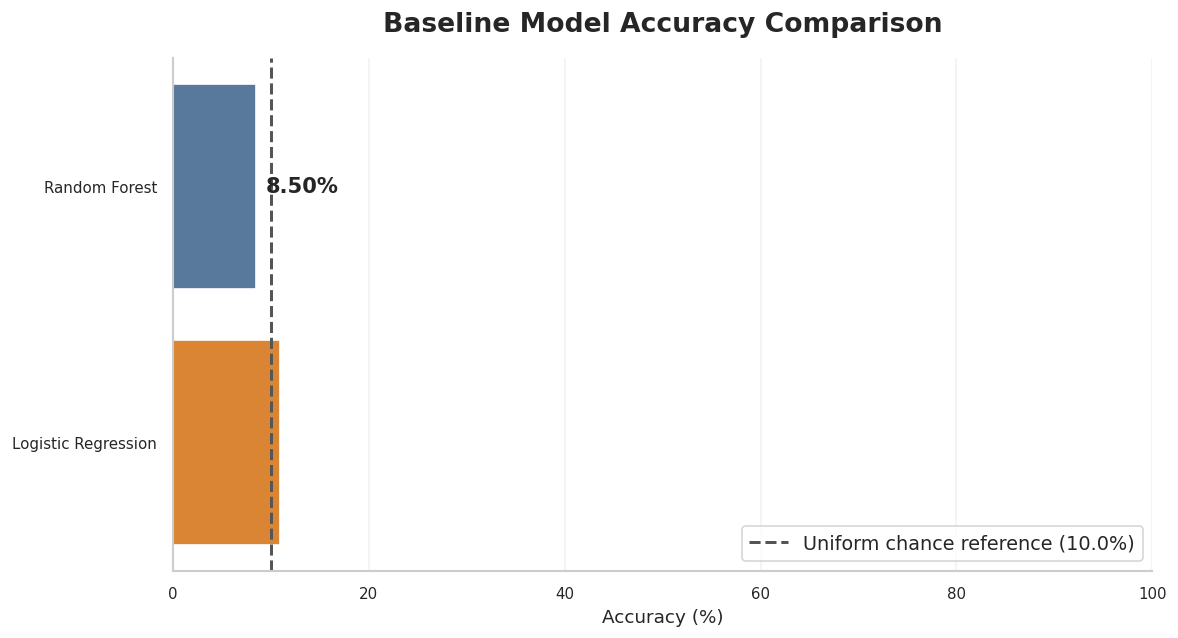

In [57]:
# Compare baseline model accuracy
models = ['Logistic Regression', 'Random Forest']
accuracies = [
    accuracy_score(y_test, lr_predictions) * 100,
    accuracy_score(y_test, rf_predictions) * 100
]

comparison_plot = pd.DataFrame({
    'Model': models,
    'Accuracy (%)': accuracies
}).sort_values('Accuracy (%)', ascending=True)

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = sns.barplot(
    data=comparison_plot,
    x='Accuracy (%)',
    y='Model',
    hue='Model',
    dodge=False,
    palette=['#4C78A8', '#F58518'],
    legend=False,
    ax=ax
)

chance_level = 100 / y.nunique()
ax.axvline(
    chance_level,
    color='#555555',
    linestyle='--',
    linewidth=1.8,
    label=f'Uniform chance reference ({chance_level:.1f}%)'
)
ax.bar_label(bars.containers[0], fmt='%.2f%%', padding=6, fontweight='bold')
ax.set_title('Baseline Model Accuracy Comparison', pad=16)
ax.set_xlabel('Accuracy (%)')
ax.set_ylabel('')
ax.set_xlim(0, max(100, max(accuracies) * 1.3))
ax.legend(frameon=True, loc='lower right')
ax.grid(axis='x', alpha=0.25)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()


In [58]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Logistic Regression evaluation

print("LOGISTIC REGRESSION RESULTS")

print("Accuracy:",
      accuracy_score(y_test, lr_predictions))

print("Precision:",
      precision_score(y_test, lr_predictions,
                      average='weighted', zero_division=0))

print("Recall:",
      recall_score(y_test, lr_predictions,
                   average='weighted', zero_division=0))

print("F1 Score:",
      f1_score(y_test, lr_predictions,
               average='weighted', zero_division=0))


# Random Forest evaluation

print("\nRANDOM FOREST RESULTS")

print("Accuracy:",
      accuracy_score(y_test, rf_predictions))

print("Precision:",
      precision_score(y_test, rf_predictions,
                      average='weighted', zero_division=0))

print("Recall:",
      recall_score(y_test, rf_predictions,
                   average='weighted', zero_division=0))

print("F1 Score:",
      f1_score(y_test, rf_predictions,
               average='weighted', zero_division=0))

LOGISTIC REGRESSION RESULTS
Accuracy: 0.11
Precision: 0.10684184236815815
Recall: 0.11
F1 Score: 0.10225541584122093

RANDOM FOREST RESULTS
Accuracy: 0.085
Precision: 0.08497669996505638
Recall: 0.085
F1 Score: 0.08462806688579665


In [59]:
print("LOGISTIC REGRESSION CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    lr_predictions,
    zero_division=0
))

print("\nRANDOM FOREST CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    rf_predictions,
    zero_division=0
))

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Cafe       0.07      0.10      0.08        21
     Chinese       0.00      0.00      0.00        21
 Continental       0.05      0.05      0.05        20
    Desserts       0.11      0.19      0.14        21
   Fast Food       0.14      0.25      0.18        20
     Italian       0.09      0.05      0.06        21
     Mexican       0.00      0.00      0.00        17
North Indian       0.12      0.05      0.07        20
South Indian       0.31      0.21      0.25        19
 Street Food       0.18      0.20      0.19        20

    accuracy                           0.11       200
   macro avg       0.11      0.11      0.10       200
weighted avg       0.11      0.11      0.10       200


RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Cafe       0.04      0.05      0.04        21
     Chinese       0.06      0.05      0.05        21

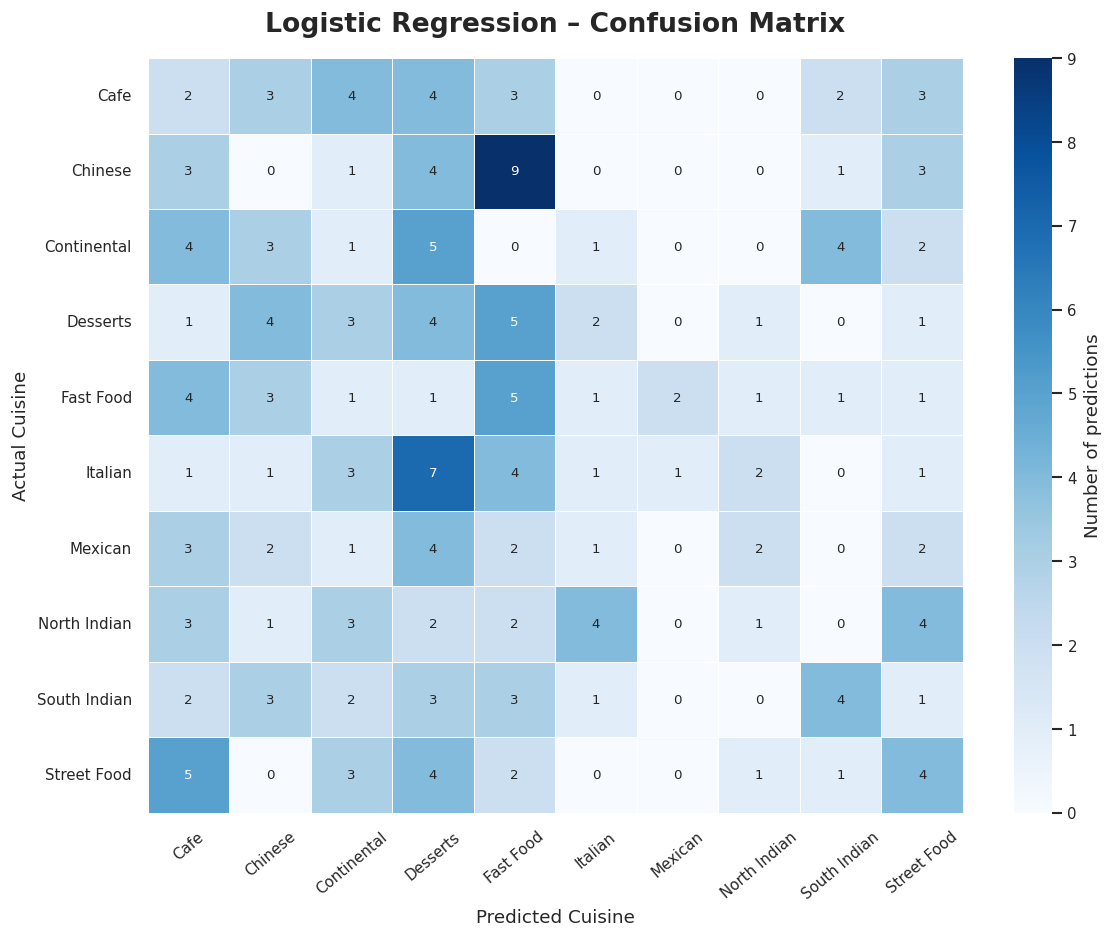

In [60]:
# Confusion matrix – Logistic Regression
class_labels = sorted(y.unique())
cm_lr = confusion_matrix(y_test, lr_predictions, labels=class_labels)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=0.5,
    linecolor='white',
    xticklabels=class_labels,
    yticklabels=class_labels,
    cbar_kws={'label': 'Number of predictions'},
    annot_kws={'size': 8},
    ax=ax
)
ax.set_title('Logistic Regression – Confusion Matrix', pad=16)
ax.set_xlabel('Predicted Cuisine')
ax.set_ylabel('Actual Cuisine')
ax.tick_params(axis='x', rotation=40)
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.show()


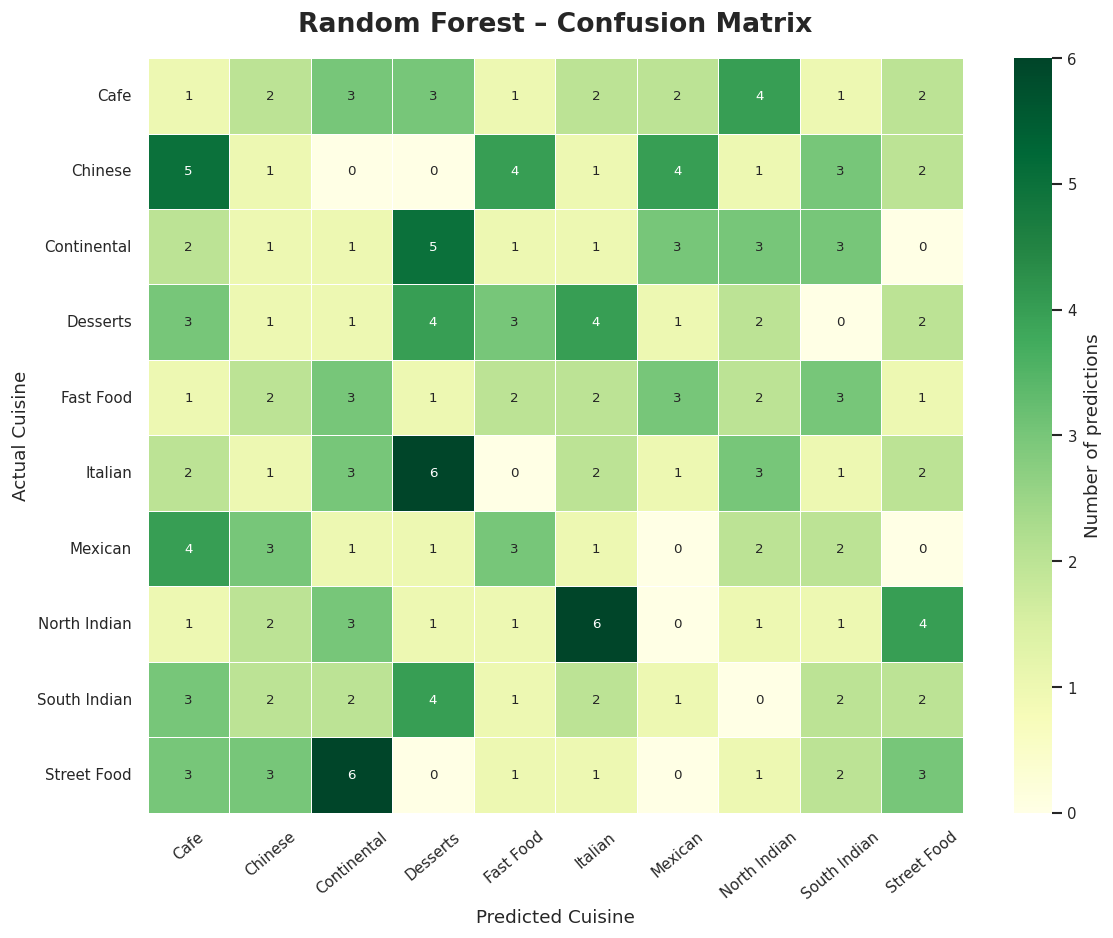

In [61]:
# Confusion matrix – Random Forest
class_labels = sorted(y.unique())
cm_rf = confusion_matrix(y_test, rf_predictions, labels=class_labels)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='YlGn',
    linewidths=0.5,
    linecolor='white',
    xticklabels=class_labels,
    yticklabels=class_labels,
    cbar_kws={'label': 'Number of predictions'},
    annot_kws={'size': 8},
    ax=ax
)
ax.set_title('Random Forest – Confusion Matrix', pad=16)
ax.set_xlabel('Predicted Cuisine')
ax.set_ylabel('Actual Cuisine')
ax.tick_params(axis='x', rotation=40)
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.show()


In [62]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],

    'Accuracy': [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions)
    ],

    'Precision': [
        precision_score(y_test, lr_predictions,
                        average='weighted', zero_division=0),
        precision_score(y_test, rf_predictions,
                        average='weighted', zero_division=0)
    ],

    'Recall': [
        recall_score(y_test, lr_predictions,
                     average='weighted', zero_division=0),
        recall_score(y_test, rf_predictions,
                     average='weighted', zero_division=0)
    ],

    'F1 Score': [
        f1_score(y_test, lr_predictions,
                 average='weighted', zero_division=0),
        f1_score(y_test, rf_predictions,
                 average='weighted', zero_division=0)
    ]
})

print(results)

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression     0.110   0.106842   0.110  0.102255
1        Random Forest     0.085   0.084977   0.085  0.084628


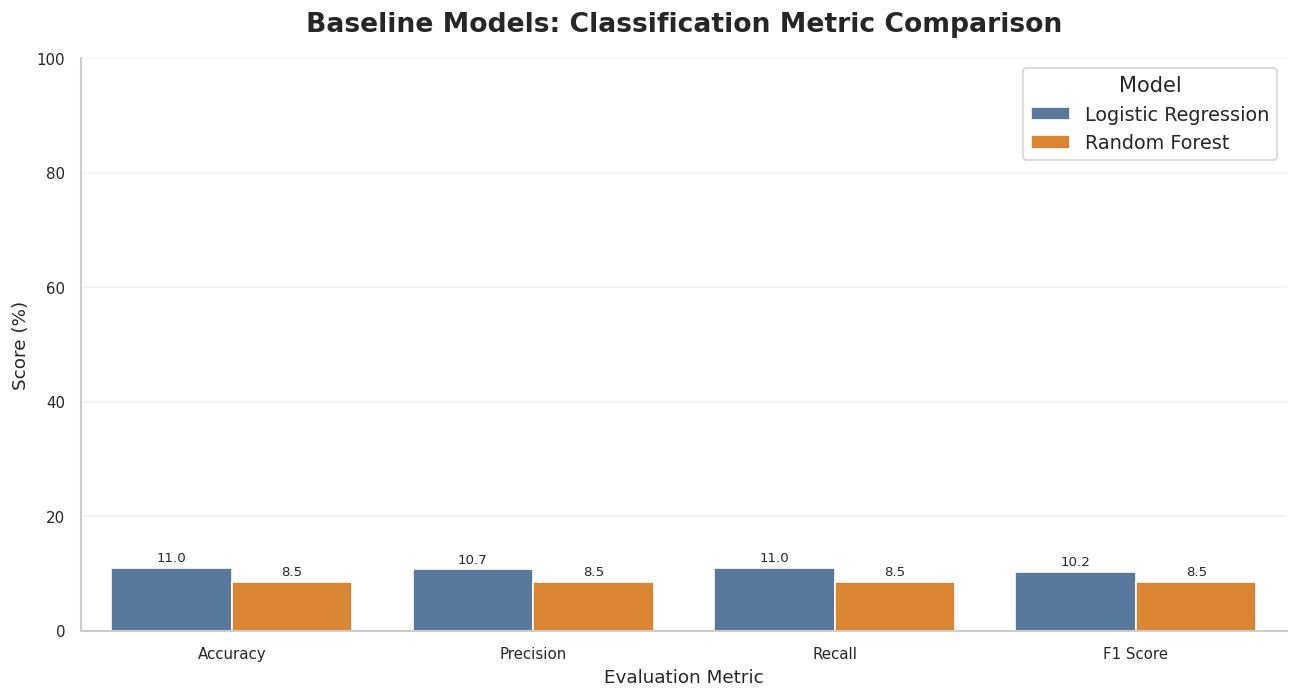

In [63]:
# Compare all evaluation metrics across baseline models
metric_plot = results.melt(
    id_vars='Model',
    value_vars=['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    var_name='Metric',
    value_name='Score'
)
metric_plot['Score'] = metric_plot['Score'] * 100

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(
    data=metric_plot,
    x='Metric',
    y='Score',
    hue='Model',
    palette=['#4C78A8', '#F58518'],
    ax=ax
)

ax.set_title('Baseline Models: Classification Metric Comparison', pad=16)
ax.set_xlabel('Evaluation Metric')
ax.set_ylabel('Score (%)')
ax.set_ylim(0, 100)
ax.legend(title='Model', frameon=True)
ax.grid(axis='y', alpha=0.25)
ax.grid(axis='x', visible=False)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=2, fontsize=8)

plt.tight_layout()
plt.show()


In [64]:
from sklearn.metrics import classification_report

# Generate classification report

report = classification_report(
    y_test,
    rf_predictions,
    output_dict=True,
    zero_division=0
)

# Convert report into DataFrame

report_df = pd.DataFrame(report).transpose()

# Display cuisine-wise performance

print("Cuisine-wise Performance Analysis:")

print(report_df.iloc[:-3][
    ['precision', 'recall', 'f1-score', 'support']
])

Cuisine-wise Performance Analysis:
              precision    recall  f1-score  support
Cafe           0.040000  0.047619  0.043478     21.0
Chinese        0.055556  0.047619  0.051282     21.0
Continental    0.043478  0.050000  0.046512     20.0
Desserts       0.160000  0.190476  0.173913     21.0
Fast Food      0.117647  0.100000  0.108108     20.0
Italian        0.090909  0.095238  0.093023     21.0
Mexican        0.000000  0.000000  0.000000     17.0
North Indian   0.052632  0.050000  0.051282     20.0
South Indian   0.111111  0.105263  0.108108     19.0
Street Food    0.166667  0.150000  0.157895     20.0


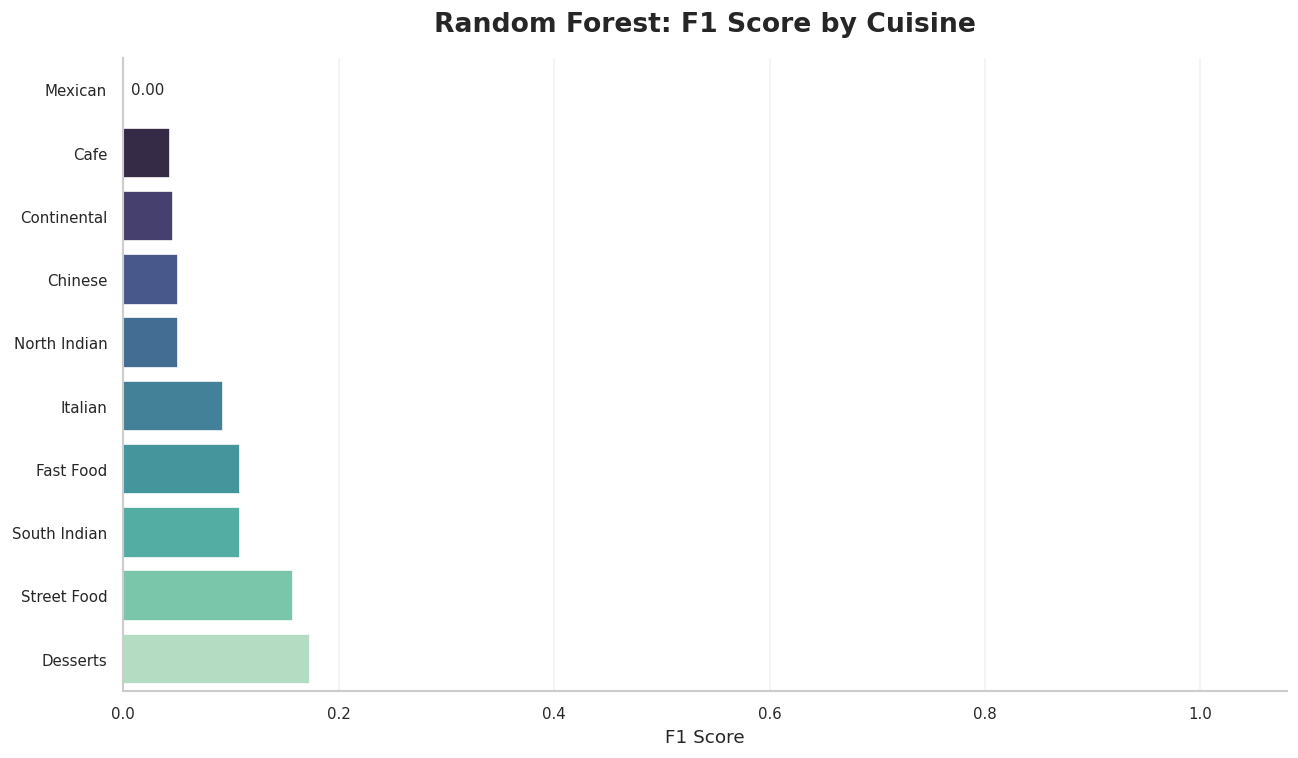

In [65]:
# Cuisine-wise F1 score – sorted horizontal bar chart
cuisine_f1 = (
    report_df.iloc[:-3]['f1-score']
    .sort_values(ascending=True)
    .rename_axis('Cuisine')
    .reset_index(name='F1 Score')
)

fig, ax = plt.subplots(figsize=(11, 6.5))
bars = sns.barplot(
    data=cuisine_f1,
    x='F1 Score',
    y='Cuisine',
    hue='Cuisine',
    dodge=False,
    palette=sns.color_palette("mako", n_colors=len(cuisine_f1)),
    legend=False,
    ax=ax
)

ax.bar_label(bars.containers[0], fmt='%.2f', padding=5, fontsize=9)
ax.set_title('Random Forest: F1 Score by Cuisine', pad=16)
ax.set_xlabel('F1 Score')
ax.set_ylabel('')
ax.set_xlim(0, 1.08)
ax.grid(axis='x', alpha=0.25)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()


In [66]:
cuisine_performance = report_df.iloc[:-3]

best_cuisine = cuisine_performance['f1-score'].idxmax()

worst_cuisine = cuisine_performance['f1-score'].idxmin()

print("Best Predicted Cuisine:", best_cuisine)

print("Best F1 Score:",
      round(cuisine_performance.loc[best_cuisine, 'f1-score'], 3))

print("\nWorst Predicted Cuisine:", worst_cuisine)

print("Worst F1 Score:",
      round(cuisine_performance.loc[worst_cuisine, 'f1-score'], 3))

Best Predicted Cuisine: Desserts
Best F1 Score: 0.174

Worst Predicted Cuisine: Mexican
Worst F1 Score: 0.0


In [67]:
cuisine_counts = df['Cuisines'].value_counts()

print("Most Common Cuisine:")
print(cuisine_counts.head(3))

print("\nLeast Common Cuisine:")
print(cuisine_counts.tail(3))

Most Common Cuisine:
Cuisines
Chinese     105
Desserts    103
Italian     103
Name: count, dtype: int64

Least Common Cuisine:
Cuisines
Fast Food       100
South Indian     98
Mexican          85
Name: count, dtype: int64


In [68]:
comparison = pd.DataFrame({
    'Actual Cuisine': y_test.values,
    'Predicted Cuisine': rf_predictions
})

print(comparison.head(20))

   Actual Cuisine Predicted Cuisine
0         Italian       Continental
1            Cafe       Continental
2    South Indian           Italian
3     Continental          Desserts
4     Street Food       Street Food
5        Desserts       Continental
6        Desserts         Fast Food
7            Cafe          Desserts
8            Cafe       Street Food
9            Cafe         Fast Food
10       Desserts       Street Food
11   South Indian              Cafe
12           Cafe           Chinese
13    Street Food              Cafe
14   North Indian           Italian
15        Italian              Cafe
16    Continental          Desserts
17    Continental           Mexican
18        Chinese         Fast Food
19        Italian          Desserts


Conclusion – Cuisine Classification
In this project, I developed a machine learning model to classify restaurants based on their cuisines using the Cognifyz restaurant dataset.

The project involved data preprocessing, exploratory data analysis, categorical feature encoding, and splitting the dataset into training and testing sets.

Two classification algorithms were implemented:
1. Logistic Regression
2. Random Forest Classifier
Both models were evaluated using accuracy, precision, recall, F1-score, and confusion matrices.

Cuisine-wise performance analysis was also conducted to understand how effectively the models classified different cuisine categories.

The project helped demonstrate the application of machine learning classification techniques in restaurant data analysis.

The results also highlighted challenges such as overlapping restaurant characteristics, limited dataset size, and potential class imbalance.